# Fake News Detection — Experiments
## Perceptron Baseline · Activation Functions · Optimizers · Regularization

This notebook runs a series of controlled experiments that directly map to the
CSE 589 lecture topics:

| Experiment | Lecture |
|---|---|
| 1 — Single-layer Perceptron as baseline | Lecture 2 |
| 2 — Activation function comparison (Sigmoid vs Tanh vs ReLU) | Lecture 3 |
| 3 — Optimizer comparison (SGD vs RMSProp vs Adam) | Lecture 4 |
| 4 — Regularization comparison (None / Dropout / L2 / Dropout+L2) | Lecture 5 |

All experiments use the **same TF-IDF features and train/test split** so results
are directly comparable.

## 0. Imports & Shared Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, classification_report

sns.set_style("whitegrid")
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
df = pd.read_csv("fake_news_data_clean.csv")

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_text"], df["label"],
    test_size=0.2, random_state=42, stratify=df["label"]
)

tfidf = TfidfVectorizer(max_features=5000, min_df=2)
X_train = tfidf.fit_transform(X_train_text).toarray()
X_test  = tfidf.transform(X_test_text).toarray()
INPUT_DIM = X_train.shape[1]

print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print(f"Vocabulary size: {INPUT_DIM}")

Train: (158, 3401)  Test: (40, 3401)
Vocabulary size: 3401


In [3]:
# Shared helper — train a model and return history + test metrics
def run_experiment(model, optimizer="adam", epochs=200, patience=15):
    model.compile(optimizer=optimizer,
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    es = EarlyStopping(monitor="val_loss", patience=patience,
                       restore_best_weights=True, verbose=0)
    history = model.fit(
        X_train, y_train,
        epochs=epochs, batch_size=16,
        validation_split=0.15,
        callbacks=[es], verbose=0
    )
    y_prob = model.predict(X_test, verbose=0).flatten()
    y_pred = (y_prob >= 0.5).astype(int)
    return {
        "history": history,
        "accuracy": accuracy_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred, average="macro"),
        "epochs": len(history.history["loss"])
    }

---
## Experiment 1 — Single-Layer Perceptron (Lecture 2)

The **perceptron** (Rosenblatt, 1958) is the simplest neural network: one layer
of weights connecting the inputs directly to the output, with no hidden layers.

**Architecture:** Input(3401) → Dense(1, sigmoid)

This is our baseline. Its limitations will justify the deeper network in Notebook 02.

In [4]:
perceptron = Sequential([
    Input(shape=(INPUT_DIM,)),
    Dense(1, activation="sigmoid")   # single layer — true perceptron
], name="Perceptron")

perceptron.summary()

Model: "Perceptron"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │         3,402 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,402 (13.29 KB)

 Trainable params: 3,402 (13.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
result_perceptron = run_experiment(perceptron)

print(f"Epochs run  : {result_perceptron['epochs']}")
print(f"Test accuracy: {result_perceptron['accuracy']:.2%}")
print(f"Macro F1    : {result_perceptron['f1']:.4f}")

Epochs run  : 200
Test accuracy: 97.50%
Macro F1    : 0.9750


---
## Experiment 2 — Activation Function Comparison (Lecture 3)

Lecture 3 introduced three activation functions:

| Function | Formula | Range | Problem |
|---|---|---|---|
| Sigmoid | $1/(1+e^{-x})$ | (0, 1) | Vanishing gradient — max derivative 0.25 |
| Tanh | $(e^x - e^{-x})/(e^x + e^{-x})$ | (-1, 1) | Vanishing gradient in deep nets |
| ReLU | $\max(0, x)$ | $[0, \infty)$ | No vanishing gradient, fast convergence |

We test all three in the **same 3-hidden-layer architecture** to see the
difference in training speed and final accuracy.

In [6]:
def make_activation_model(activation, name):
    return Sequential([
        Input(shape=(INPUT_DIM,)),
        Dense(256, activation=activation),
        Dropout(0.5),
        Dense(128, activation=activation),
        Dropout(0.5),
        Dense(64,  activation=activation),
        Dropout(0.3),
        Dense(1,   activation="sigmoid"),
    ], name=name)

act_results = {}
for act in ["sigmoid", "tanh", "relu"]:
    print(f"Training with {act} ...", end=" ")
    m = make_activation_model(act, f"model_{act}")
    act_results[act] = run_experiment(m)
    print(f"done — {act_results[act]['epochs']} epochs, acc={act_results[act]['accuracy']:.2%}")

Training with sigmoid ... 

done — 66 epochs, acc=100.00%
Training with tanh ... 

done — 20 epochs, acc=100.00%
Training with relu ... 

done — 23 epochs, acc=97.50%


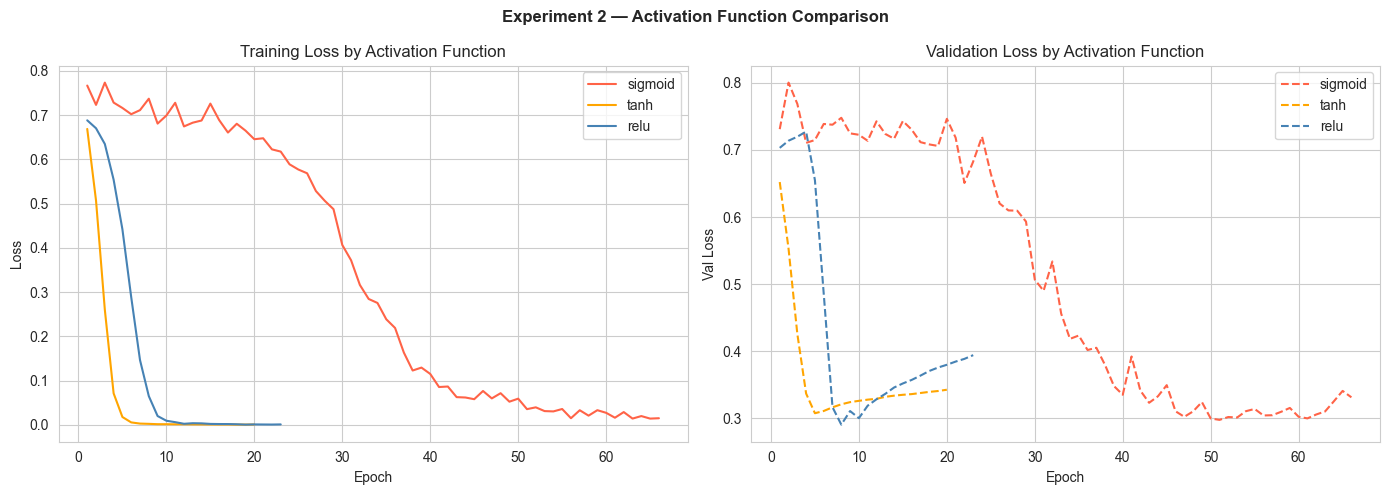


Vanishing gradient note:
Sigmoid/Tanh gradients saturate near 0, slowing learning in deep networks.
ReLU avoids this — its derivative is 1 for positive inputs, 0 otherwise.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {"sigmoid": "tomato", "tanh": "orange", "relu": "steelblue"}

for act, res in act_results.items():
    h = res["history"].history
    ep = range(1, res["epochs"] + 1)
    axes[0].plot(ep, h["loss"],     color=colors[act], label=act)
    axes[1].plot(ep, h["val_loss"], color=colors[act], label=act, linestyle="--")

axes[0].set_title("Training Loss by Activation Function")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
axes[1].set_title("Validation Loss by Activation Function")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val Loss"); axes[1].legend()

plt.suptitle("Experiment 2 — Activation Function Comparison", fontweight="bold")
plt.tight_layout()
plt.show()

print("\nVanishing gradient note:")
print("Sigmoid/Tanh gradients saturate near 0, slowing learning in deep networks.")
print("ReLU avoids this — its derivative is 1 for positive inputs, 0 otherwise.")

---
## Experiment 3 — Optimizer Comparison (Lecture 4)

Lecture 4 covered three optimizers, each an improvement on the last:

| Optimizer | Mechanism | Weakness |
|---|---|---|
| **SGD** | Fixed learning rate, one gradient step per batch | Slow, sensitive to LR choice |
| **RMSProp** | Scales LR by moving average of squared gradients | No momentum |
| **Adam** | RMSProp + momentum (best of both) | More hyperparameters |

Same architecture as Notebook 02 (256→128→64→1), only the optimizer changes.

In [8]:
def make_standard_model(name):
    return Sequential([
        Input(shape=(INPUT_DIM,)),
        Dense(256, activation="relu"), Dropout(0.5),
        Dense(128, activation="relu"), Dropout(0.5),
        Dense(64,  activation="relu"), Dropout(0.3),
        Dense(1,   activation="sigmoid"),
    ], name=name)

opt_configs = {
    "SGD":      tf.keras.optimizers.SGD(learning_rate=0.01),
    "RMSProp":  tf.keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam":     tf.keras.optimizers.Adam(learning_rate=0.001),
}

opt_results = {}
for name, opt in opt_configs.items():
    print(f"Training with {name} ...", end=" ")
    m = make_standard_model(f"model_{name}")
    opt_results[name] = run_experiment(m, optimizer=opt)
    print(f"done — {opt_results[name]['epochs']} epochs, acc={opt_results[name]['accuracy']:.2%}")

Training with SGD ... 

done — 16 epochs, acc=60.00%
Training with RMSProp ... 

done — 23 epochs, acc=97.50%
Training with Adam ... 

done — 23 epochs, acc=97.50%


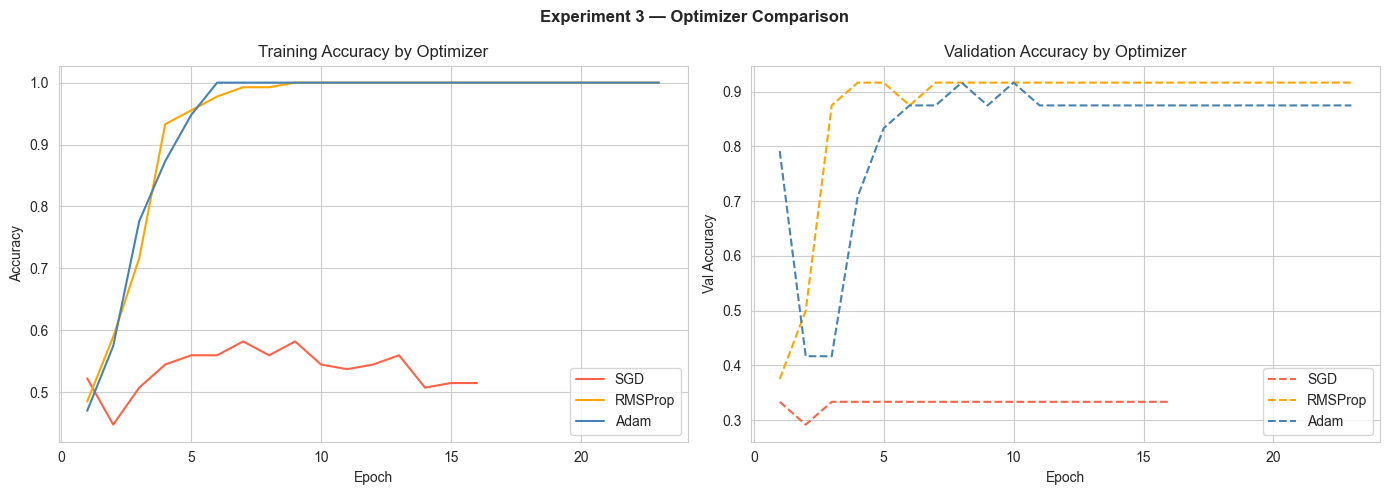

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {"SGD": "tomato", "RMSProp": "orange", "Adam": "steelblue"}

for name, res in opt_results.items():
    h = res["history"].history
    ep = range(1, res["epochs"] + 1)
    axes[0].plot(ep, h["accuracy"],     color=colors[name], label=name)
    axes[1].plot(ep, h["val_accuracy"], color=colors[name], label=name, linestyle="--")

axes[0].set_title("Training Accuracy by Optimizer")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
axes[1].set_title("Validation Accuracy by Optimizer")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val Accuracy"); axes[1].legend()

plt.suptitle("Experiment 3 — Optimizer Comparison", fontweight="bold")
plt.tight_layout()
plt.show()

---
## Experiment 4 — Regularization Comparison (Lecture 5)

Lecture 5 covered two strategies to prevent overfitting:

- **L2 weight regularization** — adds $\lambda \sum w^2$ to the loss, penalising
  large weights and pushing the model towards simpler solutions.
- **Dropout** — randomly zeros a fraction of neuron outputs each step, forcing
  the network to learn redundant representations.

We compare four configurations on the same architecture:

In [10]:
def make_reg_model(use_dropout, use_l2, name):
    l2 = regularizers.l2(1e-4) if use_l2 else None
    layers = [
        Input(shape=(INPUT_DIM,)),
        Dense(256, activation="relu", kernel_regularizer=l2),
    ]
    if use_dropout:
        layers.append(Dropout(0.5))
    layers += [
        Dense(128, activation="relu", kernel_regularizer=l2),
    ]
    if use_dropout:
        layers.append(Dropout(0.5))
    layers += [
        Dense(64, activation="relu", kernel_regularizer=l2),
    ]
    if use_dropout:
        layers.append(Dropout(0.3))
    layers.append(Dense(1, activation="sigmoid"))
    return Sequential(layers, name=name)

reg_configs = {
    "No regularization": (False, False),
    "Dropout only":      (True,  False),
    "L2 only":           (False, True),
    "Dropout + L2":      (True,  True),
}

reg_results = {}
for label, (do, l2) in reg_configs.items():
    print(f"Training [{label}] ...", end=" ")
    safe_name = label.replace(" ", "_").replace("+", "plus")
    m = make_reg_model(do, l2, safe_name)
    reg_results[label] = run_experiment(m)
    print(f"acc={reg_results[label]['accuracy']:.2%}")

Training [No regularization] ... 

acc=97.50%
Training [Dropout only] ... 

acc=97.50%
Training [L2 only] ... 

acc=97.50%
Training [Dropout + L2] ... 

acc=97.50%


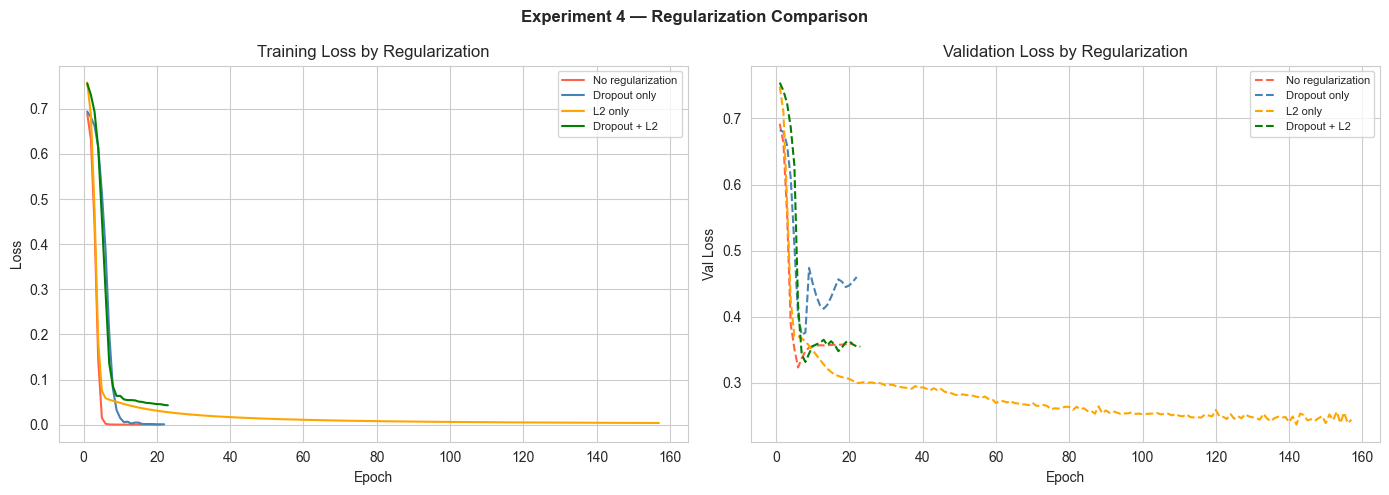

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["tomato", "steelblue", "orange", "green"]

for (label, res), color in zip(reg_results.items(), colors):
    h = res["history"].history
    ep = range(1, res["epochs"] + 1)
    axes[0].plot(ep, h["loss"],     color=color, label=label)
    axes[1].plot(ep, h["val_loss"], color=color, label=label, linestyle="--")

axes[0].set_title("Training Loss by Regularization")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend(fontsize=8)
axes[1].set_title("Validation Loss by Regularization")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val Loss"); axes[1].legend(fontsize=8)

plt.suptitle("Experiment 4 — Regularization Comparison", fontweight="bold")
plt.tight_layout()
plt.show()

---
## Summary — All Experiments

In [12]:
rows = []

# Perceptron
rows.append({
    "Experiment": "Perceptron (1 layer)",
    "Lecture": "L2",
    "Config": "Dense(1, sigmoid)",
    "Epochs": result_perceptron["epochs"],
    "Test Accuracy": f"{result_perceptron['accuracy']:.2%}",
    "Macro F1": f"{result_perceptron['f1']:.4f}",
})

# Activation functions
for act, res in act_results.items():
    rows.append({
        "Experiment": f"Activation: {act}",
        "Lecture": "L3",
        "Config": f"256→128→64 ({act})",
        "Epochs": res["epochs"],
        "Test Accuracy": f"{res['accuracy']:.2%}",
        "Macro F1": f"{res['f1']:.4f}",
    })

# Optimizers
for opt, res in opt_results.items():
    rows.append({
        "Experiment": f"Optimizer: {opt}",
        "Lecture": "L4",
        "Config": f"256→128→64 (relu, {opt})",
        "Epochs": res["epochs"],
        "Test Accuracy": f"{res['accuracy']:.2%}",
        "Macro F1": f"{res['f1']:.4f}",
    })

# Regularization
for reg, res in reg_results.items():
    rows.append({
        "Experiment": f"Reg: {reg}",
        "Lecture": "L5",
        "Config": reg,
        "Epochs": res["epochs"],
        "Test Accuracy": f"{res['accuracy']:.2%}",
        "Macro F1": f"{res['f1']:.4f}",
    })

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False))

            Experiment Lecture                     Config  Epochs Test Accuracy Macro F1
  Perceptron (1 layer)      L2          Dense(1, sigmoid)     200        97.50%   0.9750
   Activation: sigmoid      L3       256→128→64 (sigmoid)      66       100.00%   1.0000
      Activation: tanh      L3          256→128→64 (tanh)      20       100.00%   1.0000
      Activation: relu      L3          256→128→64 (relu)      23        97.50%   0.9750
        Optimizer: SGD      L4     256→128→64 (relu, SGD)      16        60.00%   0.5442
    Optimizer: RMSProp      L4 256→128→64 (relu, RMSProp)      23        97.50%   0.9750
       Optimizer: Adam      L4    256→128→64 (relu, Adam)      23        97.50%   0.9750
Reg: No regularization      L5          No regularization      21        97.50%   0.9750
     Reg: Dropout only      L5               Dropout only      22        97.50%   0.9750
          Reg: L2 only      L5                    L2 only     157        97.50%   0.9750
     Reg: Dropout + L